In [3]:
import importlib_resources
import tensorflow_datasets as tfds

print("Import successful!")
print("TFDS version:", tfds.__version__)

Import successful!
TFDS version: 4.9.10


In [4]:
(train_ds, info) = tfds.load(
    'tf_flowers',
    split='train',
    as_supervised=True,
    with_info=True
)

print(info)

I0000 00:00:1793470362.737602  151056 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793470362.738112  151056 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793470362.768223  151056 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793470363.715619  151056 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

tfds.core.DatasetInfo(
    name='tf_flowers',
    full_name='tf_flowers/3.0.1',
    description="""
    A large set of images of flowers
    """,
    homepage='https://www.tensorflow.org/tutorials/load_data/images',
    data_dir='/home/daoudi/tensorflow_datasets/tf_flowers/3.0.1',
    file_format=tfrecord,
    download_size=218.21 MiB,
    dataset_size=221.83 MiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=5),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'train': <SplitInfo num_examples=3670, num_shards=2>,
    },
    citation="""@ONLINE {tfflowers,
    author = "The TensorFlow Team",
    title = "Flowers",
    month = "jan",
    year = "2019",
    url = "http://download.tensorflow.org/example_images/flower_photos.tgz" }""",
)


E0000 00:00:1793470365.140589  151056 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



In [5]:
print(train_ds.take(1))  # Print the first example in the training dataset

<_TakeDataset element_spec=(TensorSpec(shape=(None, None, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))>


In [7]:
print(info.features)

# Or check the total number of examples in the training split
print("Total examples:", info.splits['train'].num_examples)

FeaturesDict({
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=5),
})
Total examples: 3670


I0000 00:00:1793469412.549555  149635 tf_record_dataset_op.cc:398] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


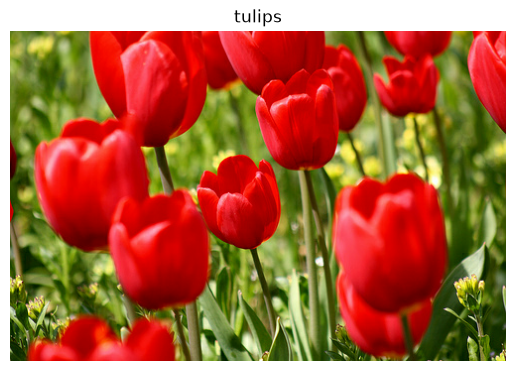

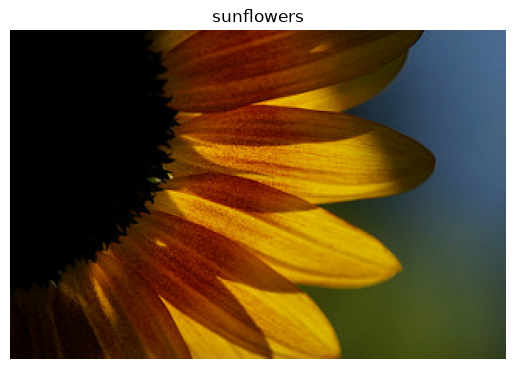

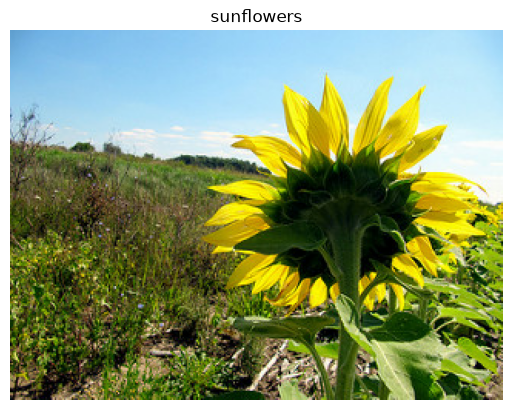

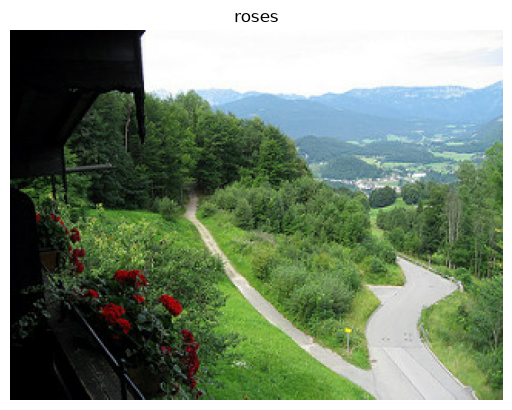

W0000 00:00:1793469413.089882  149641 cache_dataset_ops.cc:956] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`, or if downstream operations drop elements (e.g. `batch(drop_remainder=True)`). You should use `dataset.take(k).cache().repeat()` instead, or ensure the dataset size is a multiple of the batch size before caching. Another common workaround is to place the `.cache()` operation after the operation that drops elements (like `.batch(...)`), if caching the transformed data is acceptable.


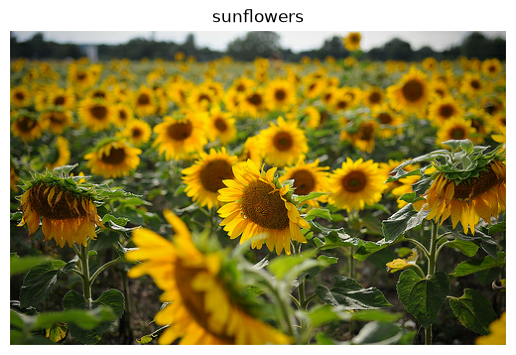

In [12]:
import matplotlib.pyplot as plt

class_names = [
    'dandelion',
    'daisy',
    'tulips',
    'sunflowers',
    'roses'
]

for image, label in train_ds.take(5):

    plt.imshow(image)
    plt.title(class_names[label.numpy()])
    plt.axis('off')
    plt.show()